# Acquisition Quality: GP qLogEI vs BNN qLogEI

这个实验只从 acquisition 的角度比较 GP 和 BNN。

核心问题不是 surrogate 的 RMSE，而是：在同样已有数据 `D_t` 下，GP acquisition 和 BNN acquisition 给出的下一个候选点，哪一个在真实缓存目标上更值得仿真？

For each seed and training size `t`, both methods receive the same observed set `D_t`, the same remaining candidate pool, and the same BCLF scalar objective. Each acquisition selects one next candidate; the notebook then evaluates that candidate against the cached true objective and reports rank/improvement metrics.


In [1]:
from __future__ import annotations

import json
import math
import sys
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start: Path) -> Path:
    candidates = [start.resolve(), *start.resolve().parents, Path('/home/zhanghf/projects/vector')]
    for candidate in candidates:
        if (candidate / 'src' / 'optimization').exists() and (candidate / 'src' / 'modeling').exists():
            return candidate
    raise RuntimeError(f'Cannot locate project root from cwd={start.resolve()}')


PROJECT_ROOT = find_project_root(Path.cwd())
SRC = PROJECT_ROOT / 'src'
for path in (PROJECT_ROOT, SRC):
    path_str = str(path)
    if path_str in sys.path:
        sys.path.remove(path_str)
    sys.path.insert(0, path_str)

from modeling import BCLFTouchstoneDatasetLoader
from optimization import (
    BCLFOptimizationSpec,
    BNNExpectedImprovementBackend,
    GPqLogEIAcquisitionBackend,
)


## Settings

`RUN_EXPERIMENT=False` keeps the notebook safe to validate. Set it to true for the full acquisition-quality campaign.


In [2]:
RUN_EXPERIMENT = True
EXPERIMENT_MODE = 'full'  # 'full' or 'smoke'

SEEDS_FULL = [0, 1, 2, 3, 4]
N_INIT = 8
BUDGET = 40
TRAIN_SIZES_FULL = list(range(N_INIT, N_INIT + BUDGET))  # D_t sizes before choosing next candidate.

DATASET_DIR = PROJECT_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
OUTPUT_DIR = PROJECT_ROOT / 'experiments' / 'acquisition_quality_gp_qlogei_vs_bnn_qlogei'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BNN_CONFIG_FULL = {
    'hidden_dims': [256, 256, 256],
    'epochs': 800,
    'update_epochs': 20,
    'warm_start': True,
    'initial_train_size': N_INIT,
    'batch_size': 1024,
    'lr': 1e-3,
    'bayesian_loss_weight': 1e-4,
    'mc_samples': 50,
    'acquisition': 'qlogei',
}
BNN_DEVICE = None

if EXPERIMENT_MODE == 'smoke':
    SEEDS = [0]
    TRAIN_SIZES = [N_INIT, N_INIT + 1]
    BNN_CONFIG = dict(BNN_CONFIG_FULL, hidden_dims=[8], epochs=1, update_epochs=1, mc_samples=4, batch_size=2)
else:
    SEEDS = list(SEEDS_FULL)
    TRAIN_SIZES = list(TRAIN_SIZES_FULL)
    BNN_CONFIG = dict(BNN_CONFIG_FULL)

print('run_experiment:', RUN_EXPERIMENT)
print('mode:', EXPERIMENT_MODE)
print('seeds:', SEEDS)
print('train_sizes:', (min(TRAIN_SIZES), max(TRAIN_SIZES), len(TRAIN_SIZES)))
print('output_dir:', OUTPUT_DIR)


run_experiment: True
mode: full
seeds: [0, 1, 2, 3, 4]
train_sizes: (8, 47, 40)
output_dir: /home/zhanghf/projects/vector/experiments/acquisition_quality_gp_qlogei_vs_bnn_qlogei


## Load ext Dataset And True Objective

The objective settings match the current TuRBO online BCLF target. Lower scalar objective is better.


In [3]:
dataset = BCLFTouchstoneDatasetLoader(dataset_dir=DATASET_DIR).load()
spec = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.4),
    lower_stopband_ghz=(3.6, 4.4),
    upper_stopband_ghz=(5.8, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)

X_all = np.asarray(dataset.X, dtype=float)
y_all = np.asarray([spec.evaluate(dataset.freqs, dataset.s_params[i]).scalar_objective() for i in range(dataset.n_samples)], dtype=float)
case_ids = list(dataset.case_ids)

print('samples:', dataset.n_samples)
print('variables:', dataset.variable_order)
print('freq_points:', dataset.n_freqs)
print('objective range:', float(np.nanmin(y_all)), float(np.nanmedian(y_all)), float(np.nanmax(y_all)))


samples: 347
variables: ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']
freq_points: 401
objective range: -23.84930491778349 30.495610109810045 149.47839343848926


## Acquisition-Quality Helpers

In [4]:
def bounds_normalize(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    lo = X_all.min(axis=0)
    hi = X_all.max(axis=0)
    span = np.where(np.abs(hi - lo) < 1e-12, 1.0, hi - lo)
    return np.clip((X - lo) / span, 0.0, 1.0)


def history_from_indices(indices: np.ndarray) -> list[dict[str, Any]]:
    rows = []
    for iteration, idx in enumerate(indices):
        rows.append({
            'iteration': int(iteration),
            'objective': float(y_all[int(idx)]),
            'geometry': X_all[int(idx)].tolist(),
            'geometry_normalized': bounds_normalize(X_all[int(idx)]).reshape(-1).tolist(),
            'simulation_status': 'done',
            'case_id': case_ids[int(idx)],
        })
    return rows


def selected_index_from_geometry(geometry: np.ndarray, candidate_indices: np.ndarray) -> int:
    target = np.asarray(geometry, dtype=float).reshape(-1)
    for idx in candidate_indices:
        if np.allclose(X_all[int(idx)], target, atol=1e-9, rtol=1e-9):
            return int(idx)
    distances = np.sum((X_all[candidate_indices] - target.reshape(1, -1)) ** 2, axis=1)
    return int(candidate_indices[int(np.argmin(distances))])


def score_selection(method: str, seed: int, train_size: int, selected_idx: int, train_idx: np.ndarray, remaining_idx: np.ndarray, selection, fit_seconds: float, select_seconds: float) -> dict[str, Any]:
    remaining_objectives = y_all[remaining_idx]
    selected_objective = float(y_all[selected_idx])
    incumbent = float(np.min(y_all[train_idx]))
    best_remaining = float(np.min(remaining_objectives))
    rank_1_based = int(1 + np.count_nonzero(remaining_objectives < selected_objective))
    n_remaining = int(len(remaining_idx))
    rank_percentile = 0.0 if n_remaining <= 1 else float((rank_1_based - 1) / (n_remaining - 1))
    top5_threshold = min(5, n_remaining)
    top10_threshold = min(10, n_remaining)
    debug = dict(selection.selection_debug or {})
    runtime = debug.get('bnn_runtime') or debug.get('kernel_runtime') or {}
    return {
        'method': method,
        'seed': int(seed),
        'train_size': int(train_size),
        'n_remaining': n_remaining,
        'selected_index': int(selected_idx),
        'selected_case_id': case_ids[int(selected_idx)],
        'selected_objective': selected_objective,
        'incumbent_objective': incumbent,
        'best_remaining_objective': best_remaining,
        'median_remaining_objective': float(np.median(remaining_objectives)),
        'improvement_over_incumbent': float(incumbent - selected_objective),
        'simple_regret_to_best_remaining': float(selected_objective - best_remaining),
        'rank_1_based': rank_1_based,
        'rank_percentile': rank_percentile,
        'is_top1': bool(rank_1_based == 1),
        'is_top5': bool(rank_1_based <= top5_threshold),
        'is_top10': bool(rank_1_based <= top10_threshold),
        'predicted_mean': selection.predicted_mean,
        'predicted_uncertainty': selection.predicted_uncertainty,
        'acquisition_score': selection.acquisition_score,
        'selection_mode': debug.get('mode'),
        'fit_seconds': float(fit_seconds),
        'select_seconds': float(select_seconds),
        'fit_mode': runtime.get('fit_mode'),
        'trained_epochs': runtime.get('trained_epochs'),
        'train_count': runtime.get('train_count'),
        'device': runtime.get('device'),
    }


def build_paired(rows: list[dict[str, Any]]) -> pd.DataFrame:
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    wide = df.pivot_table(index=['seed', 'train_size'], columns='method', values='selected_objective', aggfunc='first').reset_index()
    rank_wide = df.pivot_table(index=['seed', 'train_size'], columns='method', values='rank_percentile', aggfunc='first').reset_index()
    paired = wide.merge(rank_wide, on=['seed', 'train_size'], suffixes=('_objective', '_rank_percentile'))
    if {'gp_qlogei_objective', 'bnn_qlogei_objective'}.issubset(paired.columns):
        paired['bnn_minus_gp_objective'] = paired['bnn_qlogei_objective'] - paired['gp_qlogei_objective']
        paired['winner'] = np.where(paired['bnn_minus_gp_objective'] < 0, 'bnn_qlogei', np.where(paired['bnn_minus_gp_objective'] > 0, 'gp_qlogei', 'tie'))
    return paired


## Run Acquisition Snapshot Comparison

For each seed, `D_t` is the prefix of a seed-shuffled ext dataset. The next point selected by either acquisition is **not** added to `D_t`; this isolates acquisition quality under the same observed data. The BNN backend still follows the few-shot training schedule as `t` grows: initial fit at 8 samples, then warm-start updates when one new observed sample is added.


In [5]:
rows = []

if not RUN_EXPERIMENT:
    print('RUN_EXPERIMENT=False; skipping acquisition-quality campaign.')
else:
    for seed in SEEDS:
        order = np.arange(dataset.n_samples, dtype=int)
        rng = np.random.default_rng(seed)
        rng.shuffle(order)
        bnn_backend = BNNExpectedImprovementBackend(BNN_CONFIG, device=BNN_DEVICE)

        for train_size in TRAIN_SIZES:
            train_idx = order[:train_size]
            remaining_idx = order[train_size:]
            if len(remaining_idx) == 0:
                continue
            X_train = bounds_normalize(X_all[train_idx])
            y_train = y_all[train_idx].reshape(-1, 1)
            X_remaining = X_all[remaining_idx]
            X_remaining_norm = bounds_normalize(X_remaining)
            history = history_from_indices(train_idx)

            method_backends = {
                'gp_qlogei': GPqLogEIAcquisitionBackend(),
                'bnn_qlogei': bnn_backend,
            }
            for method, backend in method_backends.items():
                fit_start = time.perf_counter()
                fit_result = backend.fit(X_train, y_train, seed=seed)
                fit_seconds = time.perf_counter() - fit_start
                if not fit_result.ready:
                    rows.append({
                        'method': method,
                        'seed': int(seed),
                        'train_size': int(train_size),
                        'status': 'fit_failed',
                        'fit_error': fit_result.error,
                        'fit_seconds': float(fit_seconds),
                    })
                    continue
                select_start = time.perf_counter()
                selection = backend.select(
                    candidates_actual=X_remaining,
                    candidates_normalized=X_remaining_norm,
                    history=history,
                    tr_debug={'tr_active': False, 'experiment': 'acquisition_quality'},
                )
                select_seconds = time.perf_counter() - select_start
                selected_idx = selected_index_from_geometry(selection.requested_geometry, remaining_idx)
                row = score_selection(method, seed, train_size, selected_idx, train_idx, remaining_idx, selection, fit_seconds, select_seconds)
                row['status'] = 'ok'
                row['fit_error'] = None
                rows.append(row)
            print(f'seed={seed} train_size={train_size} done')

rows_df = pd.DataFrame(rows)
paired_df = build_paired([row for row in rows if row.get('status') == 'ok'])
if len(rows_df):
    rows_df.to_csv(OUTPUT_DIR / 'acquisition_quality_rows.csv', index=False)
if len(paired_df):
    paired_df.to_csv(OUTPUT_DIR / 'acquisition_quality_paired.csv', index=False)
print('rows:', len(rows_df), 'paired:', len(paired_df))
if len(rows_df):
    display(rows_df.tail())


/home/zhanghf/anaconda3/envs/vector/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed=0 train_size=8 done
seed=0 train_size=9 done
seed=0 train_size=10 done
seed=0 train_size=11 done
seed=0 train_size=12 done
seed=0 train_size=13 done
seed=0 train_size=14 done
seed=0 train_size=15 done
seed=0 train_size=16 done
seed=0 train_size=17 done
seed=0 train_size=18 done
seed=0 train_size=19 done
seed=0 train_size=20 done
seed=0 train_size=21 done
seed=0 train_size=22 done
seed=0 train_size=23 done
seed=0 train_size=24 done
seed=0 train_size=25 done
seed=0 train_size=26 done
seed=0 train_size=27 done
seed=0 train_size=28 done
seed=0 train_size=29 done
seed=0 train_size=30 done
seed=0 train_size=31 done
seed=0 train_size=32 done
seed=0 train_size=33 done
seed=0 train_size=34 done
seed=0 train_size=35 done
seed=0 train_size=36 done
seed=0 train_size=37 done
seed=0 train_size=38 done
seed=0 train_size=39 done
seed=0 train_size=40 done
seed=0 train_size=41 done
seed=0 train_size=42 done
seed=0 train_size=43 done
seed=0 train_size=44 done
seed=0 train_size=45 done
seed=0 train_s

,method,seed,train_size,n_remaining,selected_index,selected_case_id,selected_objective,incumbent_objective,best_remaining_objective,median_remaining_objective,...,acquisition_score,selection_mode,fit_seconds,select_seconds,fit_mode,trained_epochs,train_count,device,status,fit_error
395,bnn_qlogei,4,45,302,29,bo_online_general_seed0_it0029,20.901675,-2.934342,-23.849305,29.808397,...,-87.336548,bnn_qlogei_discrete,0.156109,0.062034,warm_start_update,1540.0,45.0,cuda,ok,None
396,gp_qlogei,4,46,301,149,turbo_online_general_seed4_it0040,23.215364,-2.934342,-23.849305,29.860191,...,1.807263,gp_qlogei_discrete,0.560342,0.009448,None,NaN,NaN,cuda,ok,None
397,bnn_qlogei,4,46,301,127,turbo_online_general_seed4_it0018,6.103169,-2.934342,-23.849305,29.860191,...,-87.336548,bnn_qlogei_discrete,0.156758,0.063662,warm_start_update,1560.0,46.0,cuda,ok,None
398,gp_qlogei,4,47,300,149,turbo_online_general_seed4_it0040,23.215364,-2.934342,-23.849305,29.872288,...,1.993229,gp_qlogei_discrete,0.998660,0.009464,None,NaN,NaN,cuda,ok,None
399,bnn_qlogei,4,47,300,146,turbo_online_general_seed4_it0037,4.314109,-2.934342,-23.849305,29.872288,...,-87.336548,bnn_qlogei_discrete,0.154619,0.061201,warm_start_update,1580.0,47.0,cuda,ok,None


## Load Saved Results

In [6]:
rows_path = OUTPUT_DIR / 'acquisition_quality_rows.csv'
paired_path = OUTPUT_DIR / 'acquisition_quality_paired.csv'
rows_df = pd.read_csv(rows_path) if rows_path.exists() else pd.DataFrame(rows)
paired_df = pd.read_csv(paired_path) if paired_path.exists() else build_paired([row for row in rows if row.get('status') == 'ok'])
print('rows:', len(rows_df), 'paired:', len(paired_df))
if len(rows_df):
    display(rows_df.head())


rows: 400 paired: 200


,method,seed,train_size,n_remaining,selected_index,selected_case_id,selected_objective,incumbent_objective,best_remaining_objective,median_remaining_objective,...,acquisition_score,selection_mode,fit_seconds,select_seconds,fit_mode,trained_epochs,train_count,device,status,fit_error
0,gp_qlogei,0,8,339,44,bo_online_general_seed0_it0044,-0.059780,-2.50402,-23.849305,30.482969,...,2.126503,gp_qlogei_discrete,5.795067,0.105045,NaN,NaN,NaN,cuda,ok,NaN
1,bnn_qlogei,0,8,339,198,bo_online_general_seed1_it0041,23.247643,-2.50402,-23.849305,30.482969,...,-2.085898,bnn_qlogei_discrete,5.640926,0.059788,initial_fit,800.0,8.0,cuda,ok,NaN
2,gp_qlogei,0,9,338,44,bo_online_general_seed0_it0044,-0.059780,-2.50402,-23.849305,30.489289,...,2.001599,gp_qlogei_discrete,0.394208,0.010729,NaN,NaN,NaN,cuda,ok,NaN
3,bnn_qlogei,0,9,338,154,turbo_online_general_seed4_it0045,5.745744,-2.50402,-23.849305,30.489289,...,-4.851815,bnn_qlogei_discrete,0.135238,0.059183,warm_start_update,820.0,9.0,cuda,ok,NaN
4,gp_qlogei,0,10,337,44,bo_online_general_seed0_it0044,-0.059780,-2.50402,-23.849305,30.482969,...,1.753483,gp_qlogei_discrete,0.384604,0.009569,NaN,NaN,NaN,cuda,ok,NaN


## Summary Metrics

In [7]:
if rows_df.empty:
    print('No acquisition-quality rows available.')
else:
    ok = rows_df[rows_df['status'] == 'ok'].copy()
    summary = ok.groupby('method').agg(
        snapshots=('selected_objective', 'count'),
        median_selected_objective=('selected_objective', 'median'),
        mean_selected_objective=('selected_objective', 'mean'),
        median_rank_percentile=('rank_percentile', 'median'),
        mean_rank_percentile=('rank_percentile', 'mean'),
        improvement_rate=('improvement_over_incumbent', lambda s: float(np.mean(np.asarray(s, dtype=float) > 0))),
        top1_rate=('is_top1', 'mean'),
        top5_rate=('is_top5', 'mean'),
        top10_rate=('is_top10', 'mean'),
        median_regret=('simple_regret_to_best_remaining', 'median'),
        total_fit_seconds=('fit_seconds', 'sum'),
    ).reset_index()
    summary.to_csv(OUTPUT_DIR / 'acquisition_quality_summary.csv', index=False)
    display(summary)

    if not paired_df.empty and 'winner' in paired_df.columns:
        win_summary = paired_df['winner'].value_counts().rename_axis('winner').reset_index(name='count')
        display(win_summary)


,method,snapshots,median_selected_objective,mean_selected_objective,median_rank_percentile,mean_rank_percentile,improvement_rate,top1_rate,top5_rate,top10_rate,median_regret,total_fit_seconds
0,bnn_qlogei,200,27.388544,35.099898,0.460164,0.482182,0.045,0.005,0.010,0.015,51.237848,54.201250
1,gp_qlogei,200,9.601087,17.000851,0.217448,0.296408,0.055,0.000,0.015,0.015,33.450392,135.128966


,winner,count
0,gp_qlogei,133
1,bnn_qlogei,66
2,tie,1


## Plots

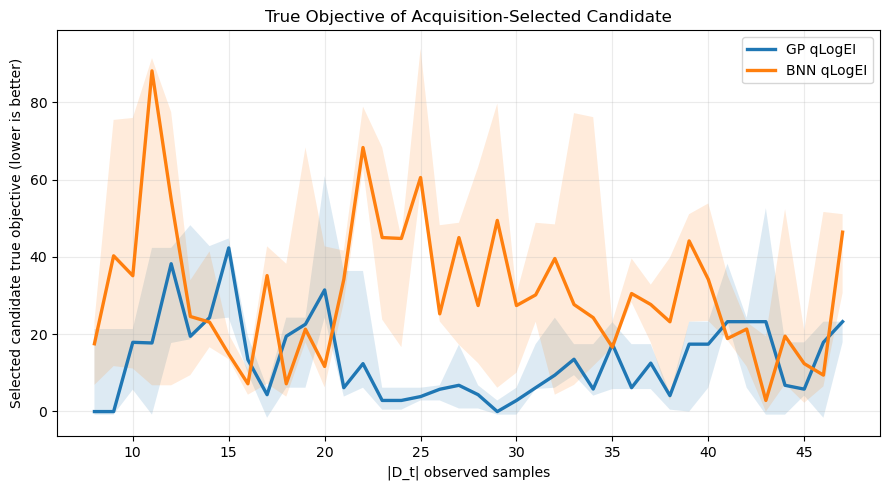

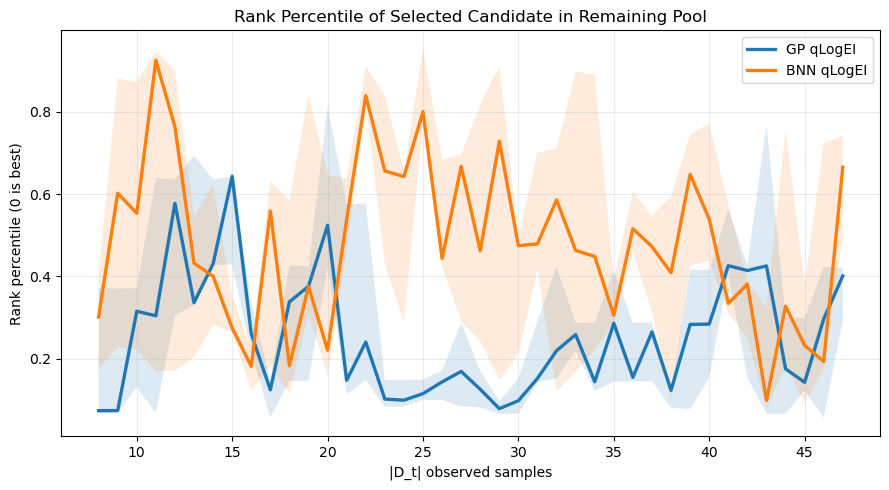

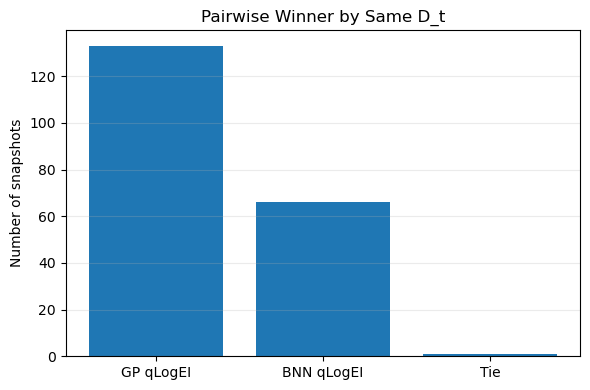

In [8]:
if rows_df.empty:
    print('No data available for plotting.')
else:
    ok = rows_df[rows_df['status'] == 'ok'].copy()
    ok['train_size'] = pd.to_numeric(ok['train_size'])

    fig, ax = plt.subplots(figsize=(9, 5))
    for method, label in [('gp_qlogei', 'GP qLogEI'), ('bnn_qlogei', 'BNN qLogEI')]:
        mdf = ok[ok['method'] == method]
        if len(mdf):
            agg = mdf.groupby('train_size')['selected_objective'].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(agg.index, agg[0.5], linewidth=2.4, label=label)
            ax.fill_between(agg.index, agg[0.25], agg[0.75], alpha=0.15)
    ax.set_title('True Objective of Acquisition-Selected Candidate')
    ax.set_xlabel('|D_t| observed samples')
    ax.set_ylabel('Selected candidate true objective (lower is better)')
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'selected_objective_by_train_size.png', dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    for method, label in [('gp_qlogei', 'GP qLogEI'), ('bnn_qlogei', 'BNN qLogEI')]:
        mdf = ok[ok['method'] == method]
        if len(mdf):
            agg = mdf.groupby('train_size')['rank_percentile'].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(agg.index, agg[0.5], linewidth=2.4, label=label)
            ax.fill_between(agg.index, agg[0.25], agg[0.75], alpha=0.15)
    ax.set_title('Rank Percentile of Selected Candidate in Remaining Pool')
    ax.set_xlabel('|D_t| observed samples')
    ax.set_ylabel('Rank percentile (0 is best)')
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'rank_percentile_by_train_size.png', dpi=180)
    plt.show()

    if not paired_df.empty and 'winner' in paired_df.columns:
        counts = paired_df['winner'].value_counts().reindex(['gp_qlogei', 'bnn_qlogei', 'tie']).fillna(0)
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.bar(['GP qLogEI', 'BNN qLogEI', 'Tie'], counts.to_numpy())
        ax.set_title('Pairwise Winner by Same D_t')
        ax.set_ylabel('Number of snapshots')
        ax.grid(True, axis='y', alpha=0.25)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / 'pairwise_win_counts.png', dpi=180)
        plt.show()
